<a href="https://colab.research.google.com/github/syedaaliza152005/CVD-Risk-Prediction/blob/main/CVD.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
print("PART 1 — Dataset Description & Understanding")

PART 1 — Dataset Description & Understanding


In [ ]:
import pandas as pd
from google.colab import files

uploaded = files.upload()

Saving Cardiovascular_Disease_Dataset.csv to Cardiovascular_Disease_Dataset (2).csv


In [ ]:
df = pd.read_csv("Cardiovascular_Disease_Dataset.csv")

df.head()

,patientid,age,gender,chestpain,restingBP,serumcholestrol,fastingbloodsugar,restingrelectro,maxheartrate,exerciseangia,oldpeak,slope,noofmajorvessels,target
0,103368,53,1,2,171,0,0,1,147,0,5.3,3,3,1
1,119250,40,1,0,94,229,0,1,115,0,3.7,1,1,0
2,119372,49,1,2,133,142,0,0,202,1,5.0,1,0,0
3,132514,43,1,0,138,295,1,1,153,0,3.2,2,2,1
4,146211,31,1,1,199,0,0,2,136,0,5.3,3,2,1


In [ ]:
df.shape

(1000, 14)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 14 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   patientid          1000 non-null   int64  
 1   age                1000 non-null   int64  
 2   gender             1000 non-null   int64  
 3   chestpain          1000 non-null   int64  
 4   restingBP          1000 non-null   int64  
 5   serumcholestrol    1000 non-null   int64  
 6   fastingbloodsugar  1000 non-null   int64  
 7   restingrelectro    1000 non-null   int64  
 8   maxheartrate       1000 non-null   int64  
 9   exerciseangia      1000 non-null   int64  
 10  oldpeak            1000 non-null   float64
 11  slope              1000 non-null   int64  
 12  noofmajorvessels   1000 non-null   int64  
 13  target             1000 non-null   int64  
dtypes: float64(1), int64(13)
memory usage: 109.5 KB


In [ ]:
df.isnull().sum()

,0
patientid,0
age,0
gender,0
chestpain,0
restingBP,0
serumcholestrol,0
fastingbloodsugar,0
restingrelectro,0
maxheartrate,0
exerciseangia,0


In [ ]:
df.duplicated().sum()

np.int64(0)

In [ ]:
df["target"].value_counts()

,count
target,
1,580
0,420


In [ ]:
df["target"].value_counts(normalize=True) * 100

,proportion
target,
1,58.0
0,42.0


In [ ]:
print("PART 2 — Data Preprocessing & Preparation")

PART 2 — Data Preprocessing & Preparation


In [ ]:
data = df.copy()

In [ ]:
data = data.drop("patientid", axis=1)

data.shape

(1000, 13)

In [ ]:
data.describe()

,age,gender,chestpain,restingBP,serumcholestrol,fastingbloodsugar,restingrelectro,maxheartrate,exerciseangia,oldpeak,slope,noofmajorvessels,target
count,1000.00000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000
mean,49.24200,0.765000,0.980000,151.747000,311.447000,0.296000,0.748000,145.477000,0.498000,2.707700,1.540000,1.222000,0.580000
std,17.86473,0.424211,0.953157,29.965228,132.443801,0.456719,0.770123,34.190268,0.500246,1.720753,1.003697,0.977585,0.493805
min,20.00000,0.000000,0.000000,94.000000,0.000000,0.000000,0.000000,71.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,34.00000,1.000000,0.000000,129.000000,235.750000,0.000000,0.000000,119.750000,0.000000,1.300000,1.000000,0.000000,0.000000
50%,49.00000,1.000000,1.000000,147.000000,318.000000,0.000000,1.000000,146.000000,0.000000,2.400000,2.000000,1.000000,1.000000
75%,64.25000,1.000000,2.000000,181.000000,404.250000,1.000000,1.000000,175.000000,1.000000,4.100000,2.000000,2.000000,1.000000
max,80.00000,1.000000,3.000000,200.000000,602.000000,1.000000,2.000000,202.000000,1.000000,6.200000,3.000000,3.000000,1.000000


In [ ]:
(data["serumcholestrol"] == 0).sum()

np.int64(53)

In [ ]:
import numpy as np

data["serumcholestrol"] = data["serumcholestrol"].replace(0, np.nan)

In [ ]:
data["serumcholestrol"].isnull().sum()

np.int64(53)

In [ ]:
median_cholesterol = data["serumcholestrol"].median()

data["serumcholestrol"] = data["serumcholestrol"].fillna(median_cholesterol)

In [ ]:
data["serumcholestrol"].isnull().sum()

np.int64(0)

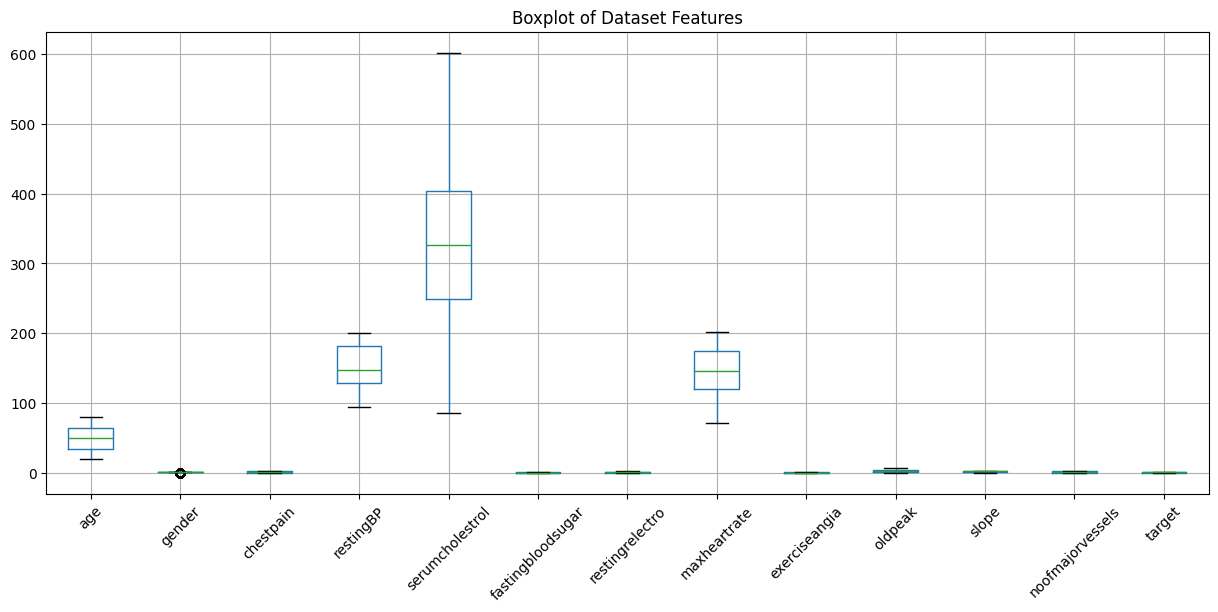

In [ ]:
import matplotlib.pyplot as plt

data.boxplot(figsize=(15, 6))
plt.xticks(rotation=45)
plt.title("Boxplot of Dataset Features")
plt.show()

In [ ]:
Q1 = data.quantile(0.25)
Q3 = data.quantile(0.75)

IQR = Q3 - Q1

outliers = ((data < (Q1 - 1.5 * IQR)) |
            (data > (Q3 + 1.5 * IQR))).sum()

outliers

,0
age,0
gender,235
chestpain,0
restingBP,0
serumcholestrol,0
fastingbloodsugar,0
restingrelectro,0
maxheartrate,0
exerciseangia,0
oldpeak,0


In [ ]:
for column in ["gender", "chestpain", "fastingbloodsugar",
               "restingrelectro", "exerciseangia", "slope"]:
    print(column, ":", sorted(data[column].unique()))

gender : [np.int64(0), np.int64(1)]
chestpain : [np.int64(0), np.int64(1), np.int64(2), np.int64(3)]
fastingbloodsugar : [np.int64(0), np.int64(1)]
restingrelectro : [np.int64(0), np.int64(1), np.int64(2)]
exerciseangia : [np.int64(0), np.int64(1)]
slope : [np.int64(0), np.int64(1), np.int64(2), np.int64(3)]


In [ ]:
X = data.drop("target", axis=1)
y = data["target"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (1000, 12)
Target shape: (1000,)


In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (800, 12)
Testing data: (200, 12)


In [ ]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [ ]:
scaler.fit_transform(X_train)

array([[ 0.15441387,  0.55617351, -1.02156212, ..., -1.04623474,
         0.45638604,  0.79018313],
       [-0.18020761,  0.55617351, -1.02156212, ..., -1.56859035,
        -1.52790109, -1.25559844],
       [ 1.66021056,  0.55617351,  2.13790836, ..., -0.93015572,
         1.4485296 ,  0.79018313],
       ...,
       [ 1.32558907, -1.79800006, -1.02156212, ..., -0.75603719,
         1.4485296 , -1.25559844],
       [ 1.49289982,  0.55617351, -1.02156212, ...,  0.6949506 ,
        -0.53575753, -1.25559844],
       [-1.07253157,  0.55617351, -1.02156212, ...,  0.81102962,
        -1.52790109, -1.25559844]])

In [ ]:
scaler.transform(X_test)

array([[-1.63023405, -1.79800006,  0.0315947 , ..., -0.52387914,
        -0.53575753, -1.25559844],
       [ 0.99096759,  0.55617351,  0.0315947 , ...,  0.52083207,
        -0.53575753, -1.25559844],
       [ 1.49289982,  0.55617351,  1.08475153, ...,  0.11455549,
         1.4485296 ,  0.79018313],
       ...,
       [-1.63023405,  0.55617351, -1.02156212, ...,  0.28867402,
        -1.52790109, -1.25559844],
       [-1.01676133,  0.55617351, -1.02156212, ..., -1.10427425,
         0.45638604, -0.23270765],
       [ 0.15441387,  0.55617351,  0.0315947 , ...,  1.27534571,
        -0.53575753,  1.81307392]])

In [ ]:
print("Scaled training data shape:", X_train_scaled.shape)
print("Scaled testing data shape:", X_test_scaled.shape)

Scaled training data shape: (800, 12)
Scaled testing data shape: (200, 12)


In [ ]:
print("PART 3 — ML Model Training & Comparison")

PART 3 — ML Model Training & Comparison


In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC

In [ ]:
logistic_model = LogisticRegression(random_state=42)
decision_tree_model = DecisionTreeClassifier(random_state=42)
random_forest_model = RandomForestClassifier(n_estimators=100, random_state=42)
svm_model = SVC(random_state=42)

In [ ]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Scaled training data shape:", X_train_scaled.shape)
print("Scaled testing data shape:", X_test_scaled.shape)

Scaled training data shape: (800, 12)
Scaled testing data shape: (200, 12)


In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC

In [ ]:
log_model = LogisticRegression(random_state=42)

log_model.fit(X_train_scaled, y_train)

LogisticRegression(random_state=42)

In [ ]:
print("Logistic Regression model trained successfully!")

Logistic Regression model trained successfully!


In [ ]:
tree_model = DecisionTreeClassifier(random_state=42)

tree_model.fit(X_train_scaled, y_train)

print("Decision Tree model trained successfully!")

Decision Tree model trained successfully!


In [ ]:
rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

rf_model.fit(X_train_scaled, y_train)

print("Random Forest model trained successfully!")

Random Forest model trained successfully!


In [ ]:
knn_model = KNeighborsClassifier(n_neighbors=5)

knn_model.fit(X_train_scaled, y_train)

print("KNN model trained successfully!")

KNN model trained successfully!


In [ ]:
svm_model = SVC(
    probability=True,
    random_state=42
)

svm_model.fit(X_train_scaled, y_train)

print("SVM model trained successfully!")

SVM model trained successfully!


In [ ]:
print("Part-4: Model Evaluation")

Part-4: Model Evaluation


In [ ]:
log_pred = log_model.predict(X_test_scaled)
tree_pred = tree_model.predict(X_test_scaled)
rf_pred = rf_model.predict(X_test_scaled)
knn_pred = knn_model.predict(X_test_scaled)
svm_pred = svm_model.predict(X_test_scaled)

print("Predictions generated successfully!")

Predictions generated successfully!


In [ ]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

results = {
    "Logistic Regression": [
        accuracy_score(y_test, log_pred),
        precision_score(y_test, log_pred),
        recall_score(y_test, log_pred),
        f1_score(y_test, log_pred)
    ],

    "Decision Tree": [
        accuracy_score(y_test, tree_pred),
        precision_score(y_test, tree_pred),
        recall_score(y_test, tree_pred),
        f1_score(y_test, tree_pred)
    ],

    "Random Forest": [
        accuracy_score(y_test, rf_pred),
        precision_score(y_test, rf_pred),
        recall_score(y_test, rf_pred),
        f1_score(y_test, rf_pred)
    ],

    "KNN": [
        accuracy_score(y_test, knn_pred),
        precision_score(y_test, knn_pred),
        recall_score(y_test, knn_pred),
        f1_score(y_test, knn_pred)
    ],

    "SVM": [
        accuracy_score(y_test, svm_pred),
        precision_score(y_test, svm_pred),
        recall_score(y_test, svm_pred),
        f1_score(y_test, svm_pred)
    ]
}

In [ ]:
comparison_df = pd.DataFrame(
    results,
    index=["Accuracy", "Precision", "Recall", "F1-score"]
).T

comparison_df

,Accuracy,Precision,Recall,F1-score
Logistic Regression,0.980,0.974576,0.991379,0.982906
Decision Tree,0.975,0.991150,0.965517,0.978166
Random Forest,0.985,0.982906,0.991379,0.987124
KNN,0.915,0.923077,0.931034,0.927039
SVM,0.970,0.958333,0.991379,0.974576


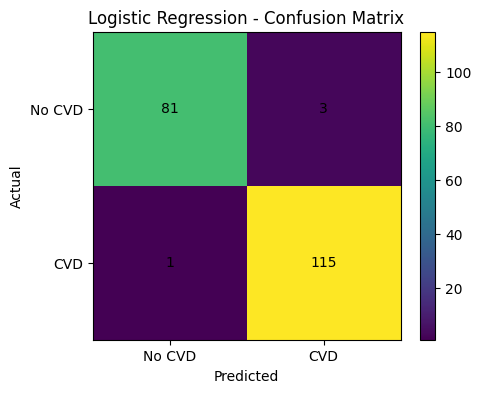

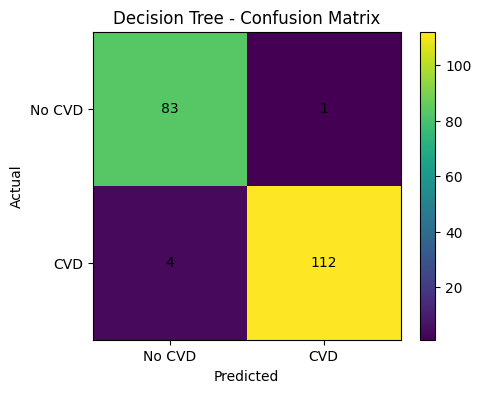

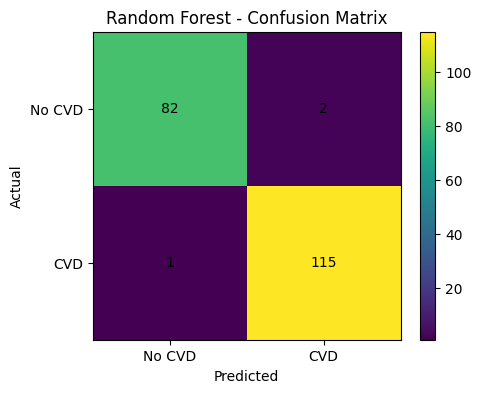

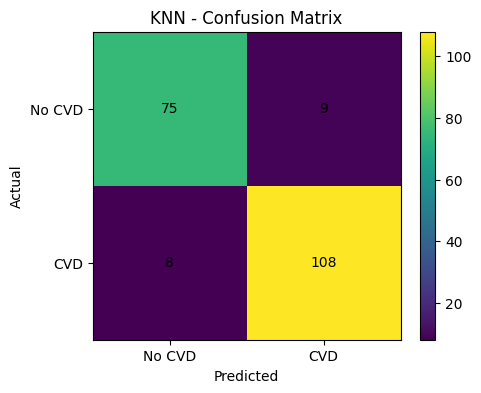

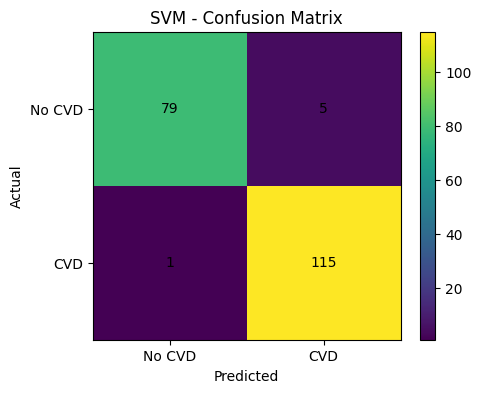

In [ ]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt

models_predictions = {
    "Logistic Regression": log_pred,
    "Decision Tree": tree_pred,
    "Random Forest": rf_pred,
    "KNN": knn_pred,
    "SVM": svm_pred
}

for name, predictions in models_predictions.items():
    cm = confusion_matrix(y_test, predictions)

    plt.figure(figsize=(5, 4))
    plt.imshow(cm)
    plt.title(f"{name} - Confusion Matrix")
    plt.xlabel("Predicted")
    plt.ylabel("Actual")

    for i in range(2):
        for j in range(2):
            plt.text(j, i, cm[i, j], ha="center", va="center")

    plt.xticks([0, 1], ["No CVD", "CVD"])
    plt.yticks([0, 1], ["No CVD", "CVD"])
    plt.colorbar()
    plt.show()

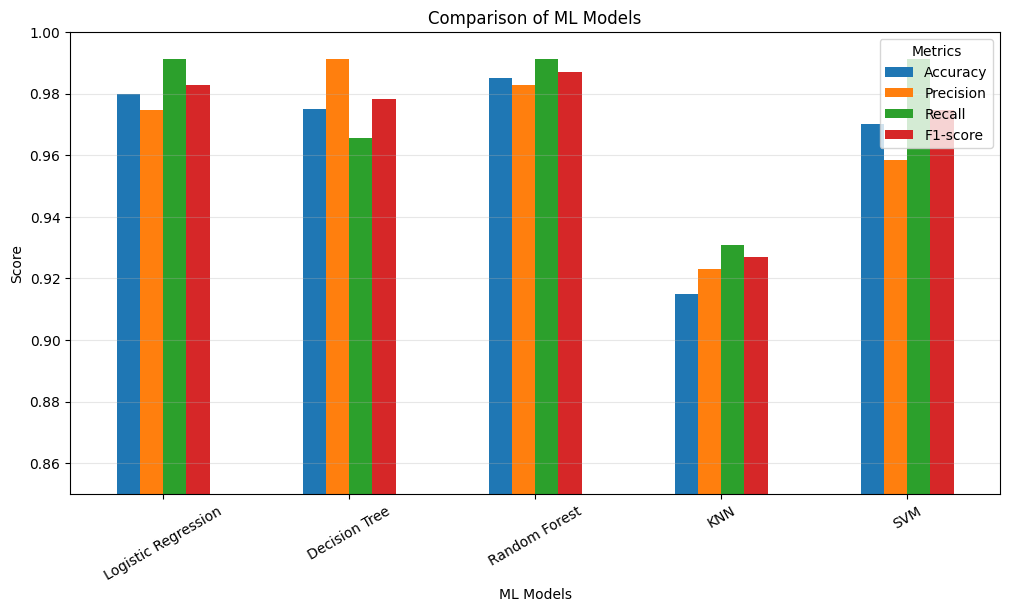

In [ ]:
comparison_df.plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Comparison of ML Models")
plt.xlabel("ML Models")
plt.ylabel("Score")
plt.xticks(rotation=30)
plt.ylim(0.85, 1.0)
plt.legend(title="Metrics")
plt.grid(axis="y", alpha=0.3)
plt.show()

In [ ]:
best_model = comparison_df["F1-score"].idxmax()
best_f1 = comparison_df["F1-score"].max()

print("Best Model:", best_model)
print("Best F1-score:", round(best_f1 * 100, 2), "%")

Best Model: Random Forest
Best F1-score: 98.71 %


In [ ]:
import joblib

joblib.dump(rf_model, "best_cvd_model.pkl")
joblib.dump(scaler, "scaler.pkl")

print("Best model and scaler saved successfully!")

Best model and scaler saved successfully!


In [ ]:
from sklearn.metrics import roc_auc_score

log_prob = log_model.predict_proba(X_test_scaled)[:, 1]
tree_prob = tree_model.predict_proba(X_test_scaled)[:, 1]
rf_prob = rf_model.predict_proba(X_test_scaled)[:, 1]
knn_prob = knn_model.predict_proba(X_test_scaled)[:, 1]
svm_prob = svm_model.predict_proba(X_test_scaled)[:, 1]

auc_results = {
    "Logistic Regression": roc_auc_score(y_test, log_prob),
    "Decision Tree": roc_auc_score(y_test, tree_prob),
    "Random Forest": roc_auc_score(y_test, rf_prob),
    "KNN": roc_auc_score(y_test, knn_prob),
    "SVM": roc_auc_score(y_test, svm_prob)
}

auc_results

{'Logistic Regression': np.float64(0.9982553366174056),
 'Decision Tree': np.float64(0.9768062397372744),
 'Random Forest': np.float64(0.9989737274220033),
 'KNN': np.float64(0.9735734811165846),
 'SVM': np.float64(0.9977422003284073)}

In [ ]:
comparison_df["ROC-AUC"] = pd.Series(auc_results)

comparison_df

,Accuracy,Precision,Recall,F1-score,ROC-AUC
Logistic Regression,0.980,0.974576,0.991379,0.982906,0.998255
Decision Tree,0.975,0.991150,0.965517,0.978166,0.976806
Random Forest,0.985,0.982906,0.991379,0.987124,0.998974
KNN,0.915,0.923077,0.931034,0.927039,0.973573
SVM,0.970,0.958333,0.991379,0.974576,0.997742


In [ ]:
for model, row in comparison_df.iterrows():
    print(f"\n{model}")
    print(f"Accuracy : {row['Accuracy']*100:.2f}%")
    print(f"Precision: {row['Precision']*100:.2f}%")
    print(f"Recall   : {row['Recall']*100:.2f}%")
    print(f"F1-score : {row['F1-score']*100:.2f}%")
    print(f"ROC-AUC  : {row['ROC-AUC']:.4f}")


Logistic Regression
Accuracy : 98.00%
Precision: 97.46%
Recall   : 99.14%
F1-score : 98.29%
ROC-AUC  : 0.9983

Decision Tree
Accuracy : 97.50%
Precision: 99.12%
Recall   : 96.55%
F1-score : 97.82%
ROC-AUC  : 0.9768

Random Forest
Accuracy : 98.50%
Precision: 98.29%
Recall   : 99.14%
F1-score : 98.71%
ROC-AUC  : 0.9990

KNN
Accuracy : 91.50%
Precision: 92.31%
Recall   : 93.10%
F1-score : 92.70%
ROC-AUC  : 0.9736

SVM
Accuracy : 97.00%
Precision: 95.83%
Recall   : 99.14%
F1-score : 97.46%
ROC-AUC  : 0.9977


In [ ]:
best_accuracy_model = comparison_df["Accuracy"].idxmax()
best_f1_model = comparison_df["F1-score"].idxmax()
best_auc_model = comparison_df["ROC-AUC"].idxmax()

print("Highest Accuracy:", best_accuracy_model)
print("Highest F1-score:", best_f1_model)
print("Highest ROC-AUC:", best_auc_model)

Highest Accuracy: Random Forest
Highest F1-score: Random Forest
Highest ROC-AUC: Random Forest


In [ ]:
comparison_df.to_csv("model_comparison_results.csv")

print("Model comparison results saved successfully!")

Model comparison results saved successfully!


In [ ]:
print("X_train exists:", "X_train" in globals())
print("X_train_scaled exists:", "X_train_scaled" in globals())
print("rf_model exists:", "rf_model" in globals())
print("scaler exists:", "scaler" in globals())

X_train exists: True
X_train_scaled exists: True
rf_model exists: True
scaler exists: True


In [ ]:
from sklearn.model_selection import train_test_split

In [ ]:
import numpy as np

data = df.drop("patientid", axis=1)

data["serumcholestrol"] = data["serumcholestrol"].replace(0, np.nan)
data["serumcholestrol"] = data["serumcholestrol"].fillna(
    data["serumcholestrol"].median()
)

print("Data preprocessing completed!")
print(data.shape)

Data preprocessing completed!
(1000, 13)


In [ ]:
X = data.drop("target", axis=1)
y = data["target"]

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (1000, 12)
y shape: (1000,)


In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Train/Test split completed!")
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)

Train/Test split completed!
X_train: (800, 12)
X_test: (200, 12)


In [ ]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Scaling completed!")
print("X_train_scaled:", X_train_scaled.shape)
print("X_test_scaled:", X_test_scaled.shape)

Scaling completed!
X_train_scaled: (800, 12)
X_test_scaled: (200, 12)


In [ ]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

rf_model.fit(X_train_scaled, y_train)

print("Random Forest trained successfully!")

Random Forest trained successfully!


In [ ]:
import joblib

joblib.dump(rf_model, "best_cvd_model.pkl")
joblib.dump(scaler, "scaler.pkl")

print("Model and scaler saved successfully!")

Model and scaler saved successfully!


In [ ]:
from google.colab import files

files.download("best_cvd_model.pkl")
files.download("scaler.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>